# 🎓 NLP Chatbot Camaba UBB 2026 — Prototipe Google Colab

**Arsitektur: Retrieval-based FAQ Chatbot** (Bi-Encoder Transformer + Semantic Search + Fine-Tuning)

---

## Kenapa arsitektur ini, bukan fine-tune model generatif?

Dataset Anda berisi **±261 pasang Q&A**. Ini terlalu kecil untuk fine-tune model generatif (T5/GPT/Llama):
model akan *overfit* lalu **berhalusinasi** — mengarang biaya UKT, tanggal SNBP, atau nama prodi yang tidak ada.
Untuk domain PMB, jawaban salah = risiko reputasi institusi.

Best practice untuk FAQ tertutup seperti ini adalah **retrieval**: pertanyaan user di-*embed*
oleh transformer, dicocokkan ke pertanyaan kanonik terdekat, lalu **jawaban asli dari Excel
dikembalikan apa adanya (verbatim)**. Nol halusinasi, jawaban selalu bisa diaudit ke sumbernya.

```
                  ┌──────────────────── Offline / build time ───────────────────┐
  Excel Q&A  ──▶  Parsing  ──▶  Augmentasi query  ──▶  Fine-tune bi-encoder (MNRL)
                                                              │
                                                              ▼
                                                    Index embedding pertanyaan
                  └──────────────────────────────────────────────────────────────┘

                  ┌───────────────────── Online / runtime ──────────────────────┐
  Query user ──▶  Normalisasi ──▶ Encode ──▶ Cosine top-k ──▶ [Cross-encoder rerank]
                                                                      │
                                             ┌────────────────────────┴────────────┐
                                    skor ≥ τ_high          τ_low ≤ skor < τ_high   skor < τ_low
                                    Jawab langsung         Tanya klarifikasi        Fallback ke
                                    (verbatim)             ("Maksud Anda ...?")     kontak PMB
                  └──────────────────────────────────────────────────────────────┘
```

## Isi notebook

| Bagian | Isi |
|---|---|
| 1–2 | Setup & parsing Excel (struktur berkategori) |
| 3 | EDA + audit kualitas data |
| 4 | Normalisasi + augmentasi query (bahasa informal, singkatan, typo) |
| 5 | Baseline TF-IDF (pembanding wajib) |
| 6 | Bi-encoder *zero-shot* (`LazarusNLP/all-indo-e5-small-v4`) |
| 7 | **Fine-tuning** dengan `MultipleNegativesRankingLoss` |
| 8 | Kalibrasi threshold + penolakan pertanyaan di luar domain |
| 9 | Cross-encoder re-ranking (opsional) |
| 10 | Kelas inference siap-produksi |
| 11 | Demo Gradio |
| 12 | Export artefak |
| 13 | Catatan menuju production |

> ⚠️ **Runtime**: `Runtime → Change runtime type → T4 GPU`. Tanpa GPU tetap jalan, hanya fine-tuning lebih lambat (~10–15 menit).

## 0. Cek Environment

In [ ]:
!nvidia-smi || echo "Tidak ada GPU — notebook tetap jalan di CPU (fine-tuning lebih lambat)."

Mon Aug 24 12:12:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Instalasi Dependensi

In [ ]:
%%capture
!pip install -q "sentence-transformers>=3.0" "transformers>=4.40" datasets accelerate openpyxl gradio scikit-learn matplotlib

In [ ]:
import os, re, json, random, unicodedata, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------
# Reproducibility: WAJIB di-set kalau hasil eval mau bisa dibandingkan
# antar eksperimen. Tanpa ini, angka akurasi akan bergoyang tiap run.
# ---------------------------------------------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------------
# CONFIG — semua hyperparameter dikumpulkan di satu tempat supaya
# eksperimen tidak perlu mengubah kode di banyak sel.
# ---------------------------------------------------------------
CFG = {
    "excel_path":     "Daftar_Pertanyaan_NLP_Chatbot_Camaba_2026_UBB.xlsx",
    "sheet_name":     0,

    # Bi-encoder berbahasa Indonesia (384-dim, ~118M param, cepat).
    # Alternatif kalau butuh akurasi lebih tinggi & tidak masalah lebih berat:
    #   "intfloat/multilingual-e5-base"          -> WAJIB pakai prefix di bawah
    #   "LazarusNLP/all-indobert-base-v4"        -> 768-dim
    #   "firqaaa/indo-sentence-bert-base"
    "model_name":     "LazarusNLP/all-indo-e5-small-v4",

    # Model keluarga E5 asli (intfloat/*) dilatih dengan prefix instruksi.
    # Varian LazarusNLP sudah di-finetune tanpa prefix -> kosongkan.
    "query_prefix":   "",     # untuk intfloat/*: "query: "
    "doc_prefix":     "",     # untuk intfloat/*: "passage: "

    "test_size":      0.2,    # proporsi PERTANYAAN (bukan varian) untuk test
    "epochs":         5,
    "batch_size":     32,
    "lr":             2e-5,
    "warmup_ratio":   0.1,
    "top_k":          5,

    "output_dir":     "artifacts",
}
Path(CFG["output_dir"]).mkdir(exist_ok=True)

print(f"Device      : {DEVICE}")
print(f"Torch       : {torch.__version__}")
import sentence_transformers as st_lib
print(f"SBERT       : {st_lib.__version__}")

Device      : cuda
Torch       : 2.11.0+cu128
SBERT       : 5.7.0


## 2. Load & Parsing Dataset

File Excel Anda **bukan tabel datar**. Strukturnya bertingkat:

```
A. Informasi Umum Universitas      <- kategori   (hanya kolom A terisi)
No | Pertanyaan | Jawaban | Sumber <- baris header (berulang tiap seksi)
1  | Apa itu ...| ...     | ...    <- data
...
D. Jalur Masuk                     <- kategori
SNBP                               <- SUB-kategori (hanya kolom A terisi)
No | Pertanyaan | Jawaban | Sumber
```

`pd.read_excel()` polos akan mencampur baris header & judul seksi ke dalam data.
Parser di bawah membaca baris demi baris sambil menahan state kategori/sub-kategori,
sehingga tiap Q&A ikut membawa metadata kategorinya — berguna untuk filtering,
analitik, dan routing eskalasi nanti.

In [ ]:
# --- Opsi A: upload manual dari komputer ---
from google.colab import files
if not Path(CFG["excel_path"]).exists():
    uploaded = files.upload()
    CFG["excel_path"] = list(uploaded.keys())[0]

# --- Opsi B: dari Google Drive (buka komentar bila perlu) ---
# from google.colab import drive
# drive.mount('/content/drive')
# CFG["excel_path"] = "/content/drive/MyDrive/UBB/Daftar_Pertanyaan_NLP_Chatbot_Camaba_2026_UBB.xlsx"

print("Dataset:", CFG["excel_path"])

Saving Daftar Pertanyaan NLP Chatbot Camaba 2026 UBB.xlsx to Daftar Pertanyaan NLP Chatbot Camaba 2026 UBB.xlsx
Dataset: Daftar Pertanyaan NLP Chatbot Camaba 2026 UBB.xlsx


In [ ]:
from openpyxl import load_workbook

# Regex judul kategori: "A. ", "Z. ", "AA. ", "AC. " -> 1-2 huruf kapital + titik + spasi
KATEGORI_RE = re.compile(r"^[A-Z]{1,2}\.\s+\S")
HEADER_TOKENS = {"no", "pertanyaan", "jawaban", "sumber"}


def parse_faq_excel(path, sheet=0):
    """
    Parser stateful untuk Excel FAQ berstruktur seksi.

    Mengembalikan (DataFrame, list_of_warnings).
    Kolom: id, kategori, sub_kategori, pertanyaan, jawaban, sumber, baris_excel
    """
    wb = load_workbook(path, read_only=True, data_only=True)
    ws = wb[wb.sheetnames[sheet]] if isinstance(sheet, int) else wb[sheet]

    rows, warns = [], []
    kategori, sub_kategori = None, None

    for i, raw in enumerate(ws.iter_rows(values_only=True), start=1):
        cells = [("" if c is None else str(c).strip()) for c in raw]
        cells += [""] * (4 - len(cells))          # pastikan minimal 4 kolom
        no, pertanyaan, jawaban, sumber = cells[:4]

        if not any(cells):                        # baris pemisah kosong
            continue

        # Baris judul: hanya kolom A yang terisi
        if no and not pertanyaan and not jawaban:
            if KATEGORI_RE.match(no):
                kategori, sub_kategori = no, None
            else:
                sub_kategori = no
            continue

        # Baris header tabel yang berulang di tiap seksi
        if no.lower() in HEADER_TOKENS and pertanyaan.lower() in HEADER_TOKENS:
            continue

        if pertanyaan and jawaban:
            rows.append({
                "kategori":     kategori or "(tanpa kategori)",
                "sub_kategori": sub_kategori or "",
                "pertanyaan":   " ".join(pertanyaan.split()),
                "jawaban":      " ".join(jawaban.split()),
                "sumber":       " ".join(sumber.split()),
                "baris_excel":  i,
            })
        elif pertanyaan and not jawaban:
            warns.append(f"Baris {i}: pertanyaan tanpa jawaban -> {pertanyaan[:70]!r}")
        elif jawaban and not pertanyaan:
            warns.append(f"Baris {i}: jawaban tanpa pertanyaan -> {jawaban[:70]!r}")

    df = pd.DataFrame(rows)
    df.insert(0, "id", range(len(df)))
    return df, warns


df_raw, warns = parse_faq_excel(CFG["excel_path"], CFG["sheet_name"])

print(f"Q&A terparsing : {len(df_raw)}")
print(f"Kategori       : {df_raw['kategori'].nunique()}")
print(f"Sub-kategori   : {df_raw['sub_kategori'].replace('', np.nan).nunique()}")
if warns:
    print(f"\n⚠️  {len(warns)} baris bermasalah:")
    for w in warns[:10]:
        print("   ", w)

df_raw.head(3)

Q&A terparsing : 261
Kategori       : 29
Sub-kategori   : 7


,id,kategori,sub_kategori,pertanyaan,jawaban,sumber,baris_excel
0,0,A. Informasi Umum Universitas,,Apa itu Universitas Bangka Belitung?,Universitas Bangka Belitung (UBB) adalah Pergu...,Profil UBB,3
1,1,A. Informasi Umum Universitas,,Kapan Universitas Bangka Belitung berdiri?,UBB berdiri pada 12 April 2006.,Sejarah UBB,4
2,2,A. Informasi Umum Universitas,,Universitas Bangka Belitung negeri atau swasta?,Perguruan Tinggi Negeri (PTN).,Profil UBB,5


## 3. EDA & Audit Kualitas Data

Bagian ini bukan formalitas. Dua hal yang **wajib** dicek sebelum melatih apa pun:

1. **Pertanyaan duplikat** — dua baris dengan pertanyaan sama membuat model
   dihukum saat menjawab benar (ia memilih ID kembar yang "salah"). Ini membuat
   angka akurasi Anda lebih rendah dari kenyataan.
2. **Jawaban placeholder** — dataset ini mengandung banyak jawaban bertanda
   *"Perlu wawancara"*. Kalau ini dikirim ke camaba, chatbot terlihat rusak.
   Harus ditandai dan diarahkan ke fallback.

In [ ]:
import matplotlib.pyplot as plt

df = df_raw.copy()

# --- 3a. Deteksi & penanganan duplikat ---------------------------------
norm_q = df["pertanyaan"].str.lower().str.replace(r"[^\w\s]", "", regex=True).str.strip()
dupes = norm_q[norm_q.duplicated(keep=False)]

if len(dupes):
    print(f"⚠️  {norm_q.duplicated().sum()} pertanyaan duplikat ditemukan:\n")
    for key in dupes.unique():
        sub = df[norm_q == key]
        print(f"  • {key!r}")
        for _, r in sub.iterrows():
            print(f"      [baris {r.baris_excel}] {r.kategori[:30]:<32} | {r.jawaban[:60]}...")
    # Strategi: pertahankan jawaban TERPANJANG (paling informatif), buang sisanya.
    df["_norm"] = norm_q
    df["_len"]  = df["jawaban"].str.len()
    df = (df.sort_values("_len", ascending=False)
            .drop_duplicates("_norm", keep="first")
            .sort_values("baris_excel")
            .drop(columns=["_norm", "_len"])
            .reset_index(drop=True))
    df["id"] = range(len(df))
    print(f"\n→ Setelah dedup: {len(df)} Q&A")
else:
    print("✅ Tidak ada pertanyaan duplikat.")

⚠️  1 pertanyaan duplikat ditemukan:

  • 'kapan pendaftaran dibuka'
      [baris 139] F. Jadwal PMB                    | Jadwal pendaftaran berbeda untuk setiap jalur seleksi. Sebag...
      [baris 345] AC. Pertanyaan yang Sangat Ser   | Jadwal pendaftaran mengikuti jalur seleksi yang dipilih, sep...

→ Setelah dedup: 260 Q&A


In [ ]:
# --- 3b. Flag jawaban yang belum final ---------------------------------
PLACEHOLDER_PAT = r"perlu wawancara|belum ditemukan informasi|tidak ditemukan informasi"
df["butuh_verifikasi"] = df["jawaban"].str.lower().str.contains(PLACEHOLDER_PAT, regex=True)

n_flag = int(df["butuh_verifikasi"].sum())
print(f"Jawaban belum final : {n_flag} / {len(df)}  ({n_flag/len(df):.1%})")
print("\nContoh yang perlu ditindaklanjuti ke unit terkait:")
for _, r in df[df.butuh_verifikasi].head(5).iterrows():
    print(f"  • [{r.kategori[:28]}] {r.pertanyaan}")

print("\n💡 Rekomendasi: pertanyaan ini TETAP masuk index (supaya niat user tetap "
      "dikenali), tapi saat runtime jawabannya diganti pesan eskalasi ke Panitia PMB. "
      "Lihat kelas inference di Bagian 10.")

Jawaban belum final : 70 / 260  (26.9%)

Contoh yang perlu ditindaklanjuti ke unit terkait:
  • [A. Informasi Umum Universita] Berapa luas kampus?
  • [A. Informasi Umum Universita] Apa saja prestasi Universitas Bangka Belitung?
  • [A. Informasi Umum Universita] Apakah UBB memiliki kampus cabang?
  • [A. Informasi Umum Universita] Berapa jumlah mahasiswa UBB?
  • [A. Informasi Umum Universita] Berapa jumlah dosen?

💡 Rekomendasi: pertanyaan ini TETAP masuk index (supaya niat user tetap dikenali), tapi saat runtime jawabannya diganti pesan eskalasi ke Panitia PMB. Lihat kelas inference di Bagian 10.


       len_q  len_a
count  260.0  260.0
mean     3.7   31.4
std      1.0   15.0
min      2.0    4.0
25%      3.0   21.0
50%      4.0   33.0
75%      4.0   41.0
max      8.0   74.0


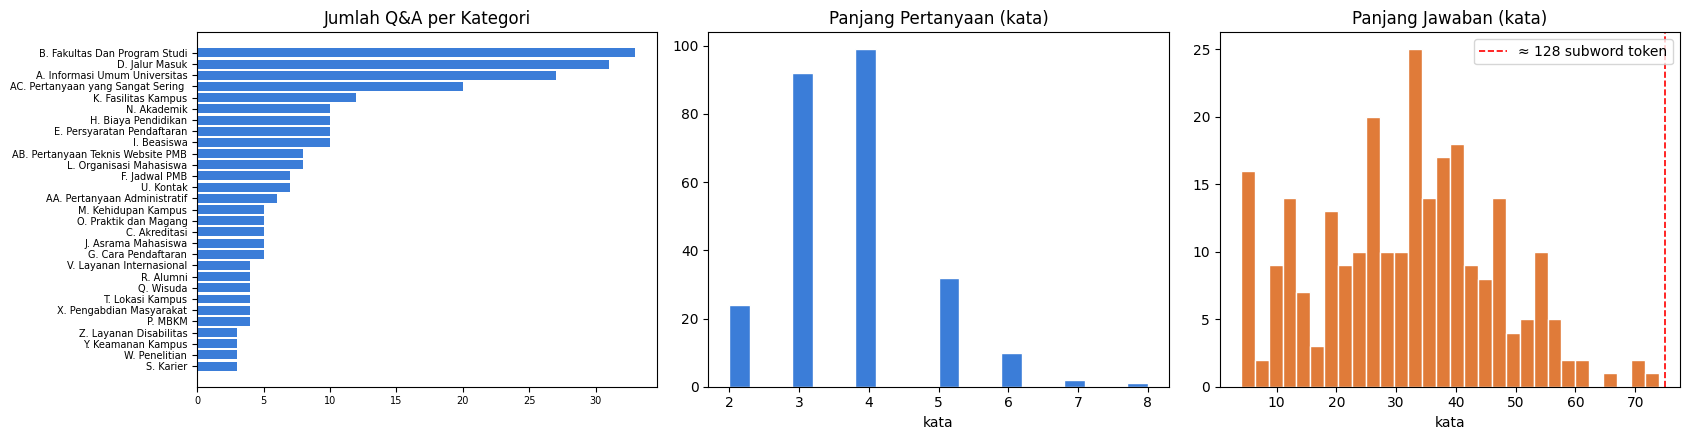


📌 Dua observasi yang menentukan desain:
   • Pertanyaan sangat pendek — median 4 kata, terpanjang 8 kata. Sinyal per query tipis, sehingga ketahanan terhadap parafrase jadi krusial.
   • Jawaban jauh lebih panjang — median 33 kata, terpanjang 74 kata (≈133 subword token, di atas max_seq_length 128 model). Jawaban terpanjang akan TERPOTONG bila di-embed.
   → Karena itu kita meng-embed PERTANYAAN, bukan jawaban. Selain menghindari pemotongan, query user memang secara semantik menyerupai pertanyaan — bukan jawaban. Jawaban cukup di-lookup lewat ID setelah pencocokan.


In [ ]:
# --- 3c. Statistik & visualisasi ---------------------------------------
df["len_q"] = df["pertanyaan"].str.split().str.len()
df["len_a"] = df["jawaban"].str.split().str.len()

print(df[["len_q", "len_a"]].describe().round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

cat_counts = df["kategori"].value_counts().sort_values()
axes[0].barh([c[:34] for c in cat_counts.index], cat_counts.values, color="#3b7dd8")
axes[0].set_title("Jumlah Q&A per Kategori"); axes[0].tick_params(labelsize=7)

axes[1].hist(df["len_q"], bins=20, color="#3b7dd8", edgecolor="white")
axes[1].set_title("Panjang Pertanyaan (kata)"); axes[1].set_xlabel("kata")

axes[2].hist(df["len_a"], bins=30, color="#e07b39", edgecolor="white")
axes[2].axvline(75, color="red", ls="--", lw=1.2, label="≈ 128 subword token")
axes[2].set_title("Panjang Jawaban (kata)"); axes[2].set_xlabel("kata"); axes[2].legend()

plt.tight_layout(); plt.show()

print("\n📌 Dua observasi yang menentukan desain:")
print(f"   • Pertanyaan sangat pendek — median {df['len_q'].median():.0f} kata, "
      f"terpanjang {df['len_q'].max()} kata. Sinyal per query tipis, sehingga "
      "ketahanan terhadap parafrase jadi krusial.")
print(f"   • Jawaban jauh lebih panjang — median {df['len_a'].median():.0f} kata, "
      f"terpanjang {df['len_a'].max()} kata (≈{df['len_a'].max()*1.8:.0f} subword "
      "token, di atas max_seq_length 128 model). Jawaban terpanjang akan TERPOTONG "
      "bila di-embed.")
print("   → Karena itu kita meng-embed PERTANYAAN, bukan jawaban. Selain menghindari "
      "pemotongan, query user memang secara semantik menyerupai pertanyaan — bukan "
      "jawaban. Jawaban cukup di-lookup lewat ID setelah pencocokan.")

## 4. Normalisasi & Augmentasi Query

### ⛔ Yang TIDAK boleh dilakukan pada transformer

Banyak tutorial NLP Indonesia menyarankan *stemming* (Sastrawi) + *stopword removal*.
Untuk model berbasis transformer itu **merusak akurasi**:

- Transformer memakai **subword tokenizer** yang sudah menangani morfologi (`pendaftaran` → `pen ##daftar ##an`).
- *Stopword* justru pembawa makna: menghapus "tidak" pada *"apakah UBB **tidak** ada S3?"* membalik artinya.
- Model di-*pretrain* pada teks natural; memberinya token cacat = *distribution shift*.

Normalisasi yang aman hanya: unicode, whitespace, casing ringan, dan ekspansi singkatan domain.

### Kenapa augmentasi wajib

Tiap intent hanya punya **satu** contoh kalimat. Camaba nyatanya mengetik seperti ini:

> *"min prodi TI akreditasi nya apa ya"* · *"brp ukt fak teknik?"* · *"pendaftran mandiri kpn dibuka"*

Kita bangkitkan varian realistis (informal, singkatan, typo, potongan kata kunci)
agar model belajar *invariansi* terhadap gaya penulisan — sekaligus menyediakan
data uji yang jujur.

In [ ]:
# ---------------------------------------------------------------
# 4a. Normalisasi teks (konservatif)
# ---------------------------------------------------------------
SINGKATAN = {
    r"\bubb\b":       "universitas bangka belitung",
    r"\bpmb\b":       "penerimaan mahasiswa baru",
    r"\bprodi\b":     "program studi",
    r"\bti\b":        "teknologi informasi",
    r"\bfak\b":       "fakultas",
    r"\bukt\b":       "uang kuliah tunggal",
    r"\bmaba\b":      "mahasiswa baru",
    r"\bcamaba\b":    "calon mahasiswa baru",
    r"\bakre\b":      "akreditasi",
    r"\bkampus\s*kite\b": "universitas bangka belitung",
}
# Slang -> baku (arah kebalikan dipakai untuk augmentasi)
SLANG = {
    r"\bgak\b": "tidak", r"\bnggak\b": "tidak", r"\bga\b": "tidak", r"\bengga\b": "tidak",
    r"\bgimana\b": "bagaimana", r"\bgmn\b": "bagaimana", r"\bbgmn\b": "bagaimana",
    r"\bbrp\b": "berapa", r"\bkpn\b": "kapan", r"\bdmn\b": "dimana",
    r"\byg\b": "yang", r"\bdgn\b": "dengan", r"\bsy\b": "saya",
    r"\bkak\b": "", r"\bmin\b": "", r"\bbang\b": "", r"\bkk\b": "",
}


def normalize(text, expand=True):
    """Normalisasi ringan. expand=True juga membakukan slang & singkatan."""
    t = unicodedata.normalize("NFKC", str(text)).lower()
    t = re.sub(r"http\S+", " ", t)
    t = re.sub(r"[^\w\s\-\?]", " ", t)          # tanda tanya dipertahankan (sinyal intent)
    if expand:
        for pat, rep in {**SLANG, **SINGKATAN}.items():
            t = re.sub(pat, rep, t)
    return re.sub(r"\s+", " ", t).strip()


for s in ["Min, brp UKT fak teknik yg S1?", "Prodi TI akreditasinya apa ya kak"]:
    print(f"{s!r}\n  -> {normalize(s)!r}\n")

'Min, brp UKT fak teknik yg S1?'
  -> 'berapa uang kuliah tunggal fakultas teknik yang s1?'

'Prodi TI akreditasinya apa ya kak'
  -> 'program studi teknologi informasi akreditasinya apa ya'



In [ ]:
# ---------------------------------------------------------------
# 4b. Augmentasi query — mensimulasikan cara camaba mengetik
# ---------------------------------------------------------------
KE_INFORMAL = {
    "bagaimana": "gimana", "berapa": "brp", "kapan": "kpn", "dimana": "dmn",
    "apakah": "apa", "yang": "yg", "dengan": "dgn", "tidak": "gak",
    "universitas bangka belitung": "ubb", "program studi": "prodi",
    "penerimaan mahasiswa baru": "pmb", "uang kuliah tunggal": "ukt",
    "teknologi informasi": "ti", "mahasiswa": "maba", "akreditasi": "akre",
    "bagaimana cara": "gmn cara", "persyaratan": "syarat",
}
PEMBUKA = ["min ", "kak ", "halo min ", "permisi ", "maaf ", ""]
PENUTUP = [" ya", " dong", " kak", " min", " ya kak", ""]
STOP_ID = {"apa", "apakah", "yang", "di", "ke", "dari", "untuk", "dan", "atau",
           "itu", "ada", "saja", "kah", "adalah", "dengan", "pada", "ya"}


def _typo(word, rng):
    """Sisipkan satu typo realistis pada kata >4 huruf."""
    if len(word) < 5:
        return word
    i = rng.randrange(1, len(word) - 1)
    mode = rng.choice(["hapus", "tukar", "ganda"])
    if mode == "hapus":
        return word[:i] + word[i+1:]
    if mode == "tukar":
        return word[:i] + word[i+1] + word[i] + word[i+2:]
    return word[:i] + word[i] + word[i:]


def augment(question, n=6, seed=0):
    """Bangkitkan n varian parafrase deterministik dari satu pertanyaan kanonik."""
    rng = random.Random(seed)
    base = question.lower().strip()
    out = set()

    # (1) Tanpa tanda baca — cara mengetik paling umum di chat
    out.add(re.sub(r"[^\w\s]", "", base).strip())

    # (2) Gaya informal / disingkat
    inf = base
    for baku, slang in KE_INFORMAL.items():
        inf = re.sub(rf"\b{re.escape(baku)}\b", slang, inf)
    out.add(re.sub(r"[^\w\s]", "", inf).strip())

    # (3) Dengan sapaan pembuka / partikel penutup
    out.add((rng.choice(PEMBUKA) + re.sub(r"[^\w\s]", "", inf) + rng.choice(PENUTUP)).strip())

    # (4) Keyword-only — user sering mengetik frasa, bukan kalimat
    kws = [w for w in re.sub(r"[^\w\s]", "", base).split() if w not in STOP_ID]
    if len(kws) >= 2:
        out.add(" ".join(kws[:5]))

    # (5) Typo pada satu kata acak
    toks = re.sub(r"[^\w\s]", "", base).split()
    if len(toks) >= 3:
        j = rng.randrange(len(toks))
        toks2 = toks.copy(); toks2[j] = _typo(toks2[j], rng)
        out.add(" ".join(toks2))

    # (6) Reframe pertanyaan
    if base.startswith("apakah"):
        out.add(re.sub(r"^apakah\s+", "", base).replace("?", "") + " ada gak")
    elif base.startswith("bagaimana"):
        out.add("cara " + re.sub(r"^bagaimana\s+(cara\s+)?", "", base).replace("?", ""))
    elif base.startswith("berapa"):
        out.add(re.sub(r"^berapa\s+", "", base).replace("?", "") + " berapa")

    out.discard(base)
    out = [v for v in out if len(v.split()) >= 2]
    return sorted(out)[:n]


demo_q = df.loc[0, "pertanyaan"]
print(f"KANONIK: {demo_q}\n")
for v in augment(demo_q, seed=0):
    print("  →", v)

KANONIK: Apa itu Universitas Bangka Belitung?

  → apa itu ubb
  → apa itu universitas bangka belitung
  → permisi apa itu ubb min
  → universitas bangka belitung


In [ ]:
# ---------------------------------------------------------------
# 4c. Split train/test DI LEVEL PERTANYAAN (bukan level varian)
#
# PENTING — sumber kebocoran data yang paling sering terjadi:
# kalau split dilakukan di level varian, varian lain dari pertanyaan
# yang sama bocor ke train. Akurasi test jadi ~99% dan menipu.
#
# Di sini seluruh 261 pertanyaan tetap ada di INDEX (memang harus,
# chatbot wajib bisa menjawab semuanya), tetapi model hanya berlatih
# dari varian pertanyaan TRAIN. Test mengukur generalisasi ke intent
# yang parafrasenya belum pernah dilihat model.
# ---------------------------------------------------------------
from sklearn.model_selection import train_test_split

train_ids, test_ids = train_test_split(
    df["id"].tolist(),
    test_size=CFG["test_size"],
    random_state=SEED,
    stratify=df["kategori"] if df["kategori"].value_counts().min() >= 2 else None,
)
train_ids, test_ids = set(train_ids), set(test_ids)

train_pairs, test_pairs = [], []
for _, r in df.iterrows():
    bucket = train_pairs if r["id"] in train_ids else test_pairs
    for v in augment(r["pertanyaan"], n=6, seed=r["id"]):
        bucket.append({"query": v, "gold_id": r["id"], "kategori": r["kategori"]})

train_df = pd.DataFrame(train_pairs)
test_df  = pd.DataFrame(test_pairs)

print(f"Pertanyaan  : {len(train_ids)} train / {len(test_ids)} test")
print(f"Varian query: {len(train_df)} train / {len(test_df)} test")
print(f"Corpus index: {len(df)} (SELURUH pertanyaan — index tidak pernah di-split)")
test_df.sample(5, random_state=SEED)

Pertanyaan  : 208 train / 52 test
Varian query: 934 train / 238 test
Corpus index: 260 (SELURUH pertanyaan — index tidak pernah di-split)


,query,gold_id,kategori
115,kak beasiswa apa saja tersedia min,128,I. Beasiswa
15,apakh ubb memiliki rumah sakit pendidikan,22,A. Informasi Umum Universitas
212,gimana mengurus surat aktif kuliah,231,AA. Pertanyaan Administratif
126,ada masjid ada gak,149,K. Fasilitas Kampus
6,brp jumlah dosen,18,A. Informasi Umum Universitas


## 5. Baseline: TF-IDF + Cosine Similarity

Selalu buat baseline non-neural dulu. Kalau transformer tidak mengalahkan TF-IDF
secara meyakinkan, kompleksitas tambahannya tidak layak dibawa ke production.

### Metrik yang dipakai

| Metrik | Arti bisnisnya |
|---|---|
| **Accuracy@1** | Jawaban pertama yang muncul benar → pengalaman user langsung beres |
| **Accuracy@3** | Jawaban benar ada di 3 teratas → cukup bagus untuk tombol "maksud Anda?" |
| **MRR** | Seberapa tinggi posisi jawaban benar rata-rata (1.0 = selalu di puncak) |

In [ ]:
# @title
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def evaluate(retrieve_fn, eval_df, k=5, name="model"):
    """
    retrieve_fn(query, k) -> list[(doc_id, score)] terurut menurun.
    Mengembalikan dict metrik dan mencetak ringkasannya.
    """
    hits1 = hits3 = 0
    rr = []
    for q, gold in zip(eval_df["query"], eval_df["gold_id"]):
        ranked = [d for d, _ in retrieve_fn(q, k)]
        hits1 += int(bool(ranked) and ranked[0] == gold)
        hits3 += int(gold in ranked[:3])
        rr.append(1.0 / (ranked.index(gold) + 1) if gold in ranked else 0.0)

    m = {"model": name,
         "Acc@1": hits1 / len(eval_df),
         "Acc@3": hits3 / len(eval_df),
         f"MRR@{k}": float(np.mean(rr))}
    print(f"{name:<34} Acc@1={m['Acc@1']:.3f}  Acc@3={m['Acc@3']:.3f}  MRR={m[f'MRR@{k}']:.3f}")
    return m


# --- Index TF-IDF (char n-gram tahan typo + word n-gram tangkap frasa) ---
corpus_norm = [normalize(q) for q in df["pertanyaan"]]

tfidf_word = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
tfidf_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
M_word = tfidf_word.fit_transform(corpus_norm)
M_char = tfidf_char.fit_transform(corpus_norm)


def retrieve_tfidf(query, k=5):
    qn = normalize(query)
    sim = (0.5 * cosine_similarity(tfidf_word.transform([qn]), M_word)[0]
         + 0.5 * cosine_similarity(tfidf_char.transform([qn]), M_char)[0])
    idx = np.argsort(-sim)[:k]
    return [(int(df.loc[i, "id"]), float(sim[i])) for i in idx]


results      = [evaluate(retrieve_tfidf, test_df, CFG["top_k"], "TF-IDF (word+char)")]

TF-IDF (word+char)                 Acc@1=0.992  Acc@3=1.000  MRR=0.996


### ⚠️ Kenapa skor TF-IDF di atas terlihat "terlalu bagus"

Perhatikan Acc@1 baseline hampir sempurna. Itu **bukan** karena TF-IDF hebat —
itu karena test set-nya terlalu mudah.

Augmentasi kita di Bagian 4 adalah **transformasi leksikal**: menghapus tanda baca,
menyingkat kata, menyisipkan typo. TF-IDF dengan `char_wb` n-gram justru dirancang
untuk membalik transformasi semacam itu. Query hasil augmentasi masih memakai
**kata-kata yang sama** dengan pertanyaan kanoniknya, sehingga pencocokan string
sudah cukup.

Camaba sungguhan tidak begitu. Mereka menulis:

> *"kuliah di sana mahal ga sih"* untuk **"Berapa UKT?"**
> *"budidaya ikan ada jurusannya?"* untuk **"Jurusan Akuakultur ada?"**

**Overlap kata: nol.** Di sinilah TF-IDF runtuh dan transformer menang — karena
transformer mencocokkan *makna*, bukan *string*.

Maka kita siapkan **test set kedua**: parafrase yang ditulis tangan, sengaja
dibuat berbeda secara leksikal. Inilah angka yang harus Anda pakai untuk
mengambil keputusan arsitektur.

In [ ]:
# ---------------------------------------------------------------
# HARD EVAL SET — parafrase tulisan manusia, overlap kata minimal.
# Dipetakan lewat TEKS pertanyaan kanonik (bukan ID) supaya tetap
# valid meski urutan baris di Excel berubah.
#
# 👉 Ini template. Perluas dengan pertanyaan camaba TAHUN LALU
#    (dari WA panitia, DM Instagram, atau formulir). Itu data emas.
# ---------------------------------------------------------------
HARD_SET = {
    "Apa itu Universitas Bangka Belitung?":        ["ubb tuh kampus apa sih", "ceritain dong tentang kampus ini"],
    "Kapan Universitas Bangka Belitung berdiri?":  ["sejak tahun berapa kampus ini ada"],
    "Universitas Bangka Belitung negeri atau swasta?": ["ubb punya pemerintah atau yayasan"],
    "Dimana lokasi kampus?":                       ["alamat lengkapnya di mana ya", "kampusnya di daerah mana"],
    "Siapa rektor UBB saat ini?":                  ["yang mimpin kampus sekarang siapa"],
    "Apakah ijazah UBB diakui?":                   ["lulusan sini gampang keterima kerja gak ijazahnya"],
    "Apakah kampus memiliki perpustakaan?":        ["tempat pinjam buku ada gak"],
    "Apakah tersedia area parkir?":                ["bawa motor ditaruh di mana"],
    "Apa itu SNBP?":                               ["jalur lewat nilai rapor tanpa tes itu apa namanya"],
    "Apa itu SNBT?":                               ["jalur yang pakai utbk maksudnya gimana"],
    "Apakah UBB membuka jalur mandiri?":           ["kalau gagal utbk masih bisa masuk lewat seleksi kampus sendiri"],
    "Beasiswa apa saja tersedia?":                 ["bantuan dana kuliah yang bisa diambil apa aja", "keringanan biaya buat yang kurang mampu ada?"],
    "Apakah tersedia asrama?":                     ["ada tempat tinggal buat anak rantau gak"],
    "Berapa biaya asrama?":                        ["sewa kamar di dalam kampus harganya berapa"],
    "Apakah ada kantin?":                          ["makan siang bisa di mana kalau di kampus"],
    "Apakah ada fasilitas olahraga?":              ["lapangan buat main futsal atau basket ada"],
    "Apa saja organisasi mahasiswa?":              ["ukm sama bem apa aja yang bisa diikuti"],
    "Apakah ada program magang?":                  ["bisa kerja praktek di perusahaan gak"],
    "Berapa lama magang?":                         ["durasi kerja praktek berapa bulan"],
    "Apa syarat wisuda?":                          ["biar bisa ikut prosesi kelulusan harus memenuhi apa"],
    "Bagaimana peluang kerja alumni?":             ["lulusan sini gampang dapat pekerjaan gak"],
    "Apakah menerima mahasiswa asing?":            ["orang luar negeri boleh kuliah di sini"],
    "Apakah ada pertukaran pelajar?":              ["bisa kuliah sementara di kampus lain gak"],
    "Apakah kampus ramah disabilitas?":            ["teman saya pakai kursi roda, kampusnya bisa diakses"],
    "Apakah ada shuttle bus?":                     ["ada antar jemput ke kampus"],
    "Mahasiswa bisa ikut penelitian?":             ["boleh gabung riset dosen gak"],
    "Ada S3?":                                     ["bisa lanjut doktor di sini"],
    "Ada D3?":                                     ["program diploma tersedia gak"],
    "Jurusan Teknik Sipil ada?":                   ["kalau mau belajar konstruksi bangunan masuk prodi apa"],
    "Jurusan Akuakultur ada?":                     ["budidaya ikan ada jurusannya"],
    "Jurusan Agroteknologi ada?":                  ["minat di bidang pertanian masuk prodi mana"],
    "Akreditasi universitas apa?":                 ["nilai mutu kampus ini dari ban-pt apa"],
    "Bagaimana cara melihat akreditasi jurusan?":  ["cek peringkat mutu prodi lewat mana"],
}

lookup = {normalize(q, expand=False): i for q, i in zip(df["pertanyaan"], df["id"])}
hard_rows, tak_ketemu = [], []
for kanonik, variasi in HARD_SET.items():
    key = normalize(kanonik, expand=False)
    if key not in lookup:
        tak_ketemu.append(kanonik); continue
    for v in variasi:
        hard_rows.append({"query": v, "gold_id": lookup[key], "kanonik": kanonik})

hard_df = pd.DataFrame(hard_rows)
print(f"Hard eval set: {len(hard_df)} query terhadap {hard_df['gold_id'].nunique()} intent")
if tak_ketemu:
    print(f"⚠️  Tidak ditemukan di dataset (teks berubah?): {tak_ketemu}")

results_hard = [evaluate(retrieve_tfidf, hard_df, CFG["top_k"], "TF-IDF (word+char)")]
print("\n👆 Bandingkan dengan skor di sel sebelumnya. Inilah jarak antara "
      "test set sintetis dan bahasa manusia sungguhan.")

Hard eval set: 36 query terhadap 33 intent
TF-IDF (word+char)                 Acc@1=0.056  Acc@3=0.083  MRR=0.069

👆 Bandingkan dengan skor di sel sebelumnya. Inilah jarak antara test set sintetis dan bahasa manusia sungguhan.


## 6. Bi-Encoder Transformer — *Zero-Shot*

Sekarang transformer-nya. **Bi-encoder** meng-encode query dan dokumen secara
terpisah menjadi vektor; kemiripan = cosine antar vektor. Karena embedding korpus
bisa dihitung sekali di muka, pencarian saat runtime sangat cepat (O(n) dot-product,
untuk 261 dokumen ≈ mikrodetik).

Model: **`LazarusNLP/all-indo-e5-small-v4`** — `intfloat/multilingual-e5-small`
yang di-fine-tune pada dataset berbahasa Indonesia. Dimensi 384, ~118M parameter,
cukup ringan untuk CPU di production.

> **Keputusan desain penting:** kita meng-embed **pertanyaan**, bukan jawaban.
> Alasannya: (a) `max_seq_length` model 128 token, banyak jawaban lebih panjang dan akan terpotong;
> (b) query user secara semantik mirip *pertanyaan*, bukan *jawaban* — mencocokkan
> query↔pertanyaan adalah perbandingan yang setara (*symmetric search*).

In [ ]:
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer(CFG["model_name"], device=DEVICE)
print(model)
print(f"\nmax_seq_length: {model.max_seq_length} token")
print(f"Dimensi embed : {model.get_sentence_embedding_dimension()}")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/176 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.37k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/965 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
)

max_seq_length: 128 token
Dimensi embed : 384


In [ ]:
def build_index(model, texts, batch_size=64):
    """Encode korpus sekali; normalisasi L2 supaya dot-product == cosine."""
    return model.encode(
        [CFG["doc_prefix"] + t for t in texts],
        batch_size=batch_size,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=True,
    )


def make_retriever(model, index_emb, ids):
    """Membuat closure retrieve(query, k) -> [(doc_id, cosine_score)]."""
    def retrieve(query, k=5):
        q = model.encode(CFG["query_prefix"] + normalize(query),
                         convert_to_tensor=True, normalize_embeddings=True)
        hits = util.semantic_search(q, index_emb, top_k=k)[0]
        return [(int(ids[h["corpus_id"]]), float(h["score"])) for h in hits]
    return retrieve


corpus_texts = [normalize(q) for q in df["pertanyaan"]]
corpus_ids   = df["id"].tolist()

index_zs = build_index(model, corpus_texts)
retrieve_zs = make_retriever(model, index_zs, corpus_ids)

print("── Test set augmentasi (mudah) ──")
results.append(evaluate(retrieve_zs, test_df, CFG["top_k"], "Bi-encoder (zero-shot)"))
print("\n── Hard set: parafrase manusia ──")
results_hard.append(evaluate(retrieve_zs, hard_df, CFG["top_k"], "Bi-encoder (zero-shot)"))

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

── Test set augmentasi (mudah) ──
Bi-encoder (zero-shot)             Acc@1=0.979  Acc@3=1.000  MRR=0.989

── Hard set: parafrase manusia ──
Bi-encoder (zero-shot)             Acc@1=0.139  Acc@3=0.333  MRR=0.257


In [ ]:
# Uji cepat dengan bahasa camaba yang sebenarnya
for q in ["min ukt di ubb brp ya",
          "prodi TI akreditasinya apa",
          "kpn pendaftran snbp dibuka",
          "ada beasiswa gak buat maba"]:
    print(f"\nQ: {q}")
    for rank, (doc_id, score) in enumerate(retrieve_zs(q, 3), 1):
        print(f"  {rank}. [{score:.3f}] {df.loc[doc_id, 'pertanyaan']}")


Q: min ukt di ubb brp ya
  1. [0.885] Berapa biaya kuliah di UBB?
  2. [0.766] Berapa UKT?
  3. [0.752] Berapa jumlah mahasiswa UBB?

Q: prodi TI akreditasinya apa
  1. [0.703] Akreditasi universitas apa?
  2. [0.685] Akreditasi jurusan saya apa?
  3. [0.661] Jurusan apa yang memiliki akreditasi unggul?

Q: kpn pendaftran snbp dibuka
  1. [0.835] Kapan SNBP dibuka?
  2. [0.716] Kapan SNBT dibuka?
  3. [0.656] Apa itu SNBP?

Q: ada beasiswa gak buat maba
  1. [0.704] Apakah ada beasiswa?
  2. [0.650] Bagaimana cara mendapatkan beasiswa?
  3. [0.610] Apakah ada beasiswa prestasi?


## 7. Fine-Tuning Bi-Encoder — `MultipleNegativesRankingLoss`

Ini inti "algoritma transformer" yang Anda minta.

### Cara kerja MNRL (dan kenapa ia cocok di sini)

Model diberi pasangan `(varian_query, pertanyaan_kanonik)`. Dalam satu batch berisi
*B* pasangan, untuk tiap *anchor* ada **1 positif** dan **B−1 negatif implisit**
(pasangan lain di batch itu). Loss-nya *cross-entropy* atas skor cosine:

$$\mathcal{L} = -\frac{1}{B}\sum_{i=1}^{B} \log \frac{e^{\cos(a_i, p_i)/\tau}}{\sum_{j=1}^{B} e^{\cos(a_i, p_j)/\tau}}$$

Keunggulannya: **tidak perlu melabeli negatif secara manual** — mahal dan rawan salah.
Konsekuensinya: **batch besar = sinyal belajar lebih kuat** (lebih banyak negatif per langkah).

⚠️ Wajib pakai `BatchSamplers.NO_DUPLICATES`. Tanpa itu, dua varian dari pertanyaan
yang sama bisa masuk satu batch — model dihukum karena menganggap keduanya mirip,
padahal memang seharusnya mirip. Sinyal training jadi rusak.

In [ ]:
from datasets import Dataset
from sentence_transformers import (SentenceTransformerTrainer,
                                   SentenceTransformerTrainingArguments, losses)
from sentence_transformers.training_args import BatchSamplers
from sentence_transformers.evaluation import InformationRetrievalEvaluator

id2q = dict(zip(df["id"], df["pertanyaan"]))

# Format MNRL: kolom (anchor, positive)
train_ds = Dataset.from_dict({
    "anchor":   [CFG["query_prefix"] + q for q in train_df["query"]],
    "positive": [CFG["doc_prefix"] + normalize(id2q[i]) for i in train_df["gold_id"]],
})

# Evaluator IR: dijalankan tiap epoch untuk memantau overfitting
ir_eval = InformationRetrievalEvaluator(
    queries={f"q{i}": CFG["query_prefix"] + q for i, q in enumerate(test_df["query"])},
    corpus={f"d{i}": CFG["doc_prefix"] + t for i, t in zip(corpus_ids, corpus_texts)},
    relevant_docs={f"q{i}": {f"d{g}"} for i, g in enumerate(test_df["gold_id"])},
    name="camaba-test", show_progress_bar=False,
)

print(f"Pasangan training : {len(train_ds)}")
print(f"Query evaluasi    : {len(test_df)}")
train_ds[0]

Pasangan training : 934
Query evaluasi    : 238


{'anchor': 'apa itu ubb', 'positive': 'apa itu universitas bangka belitung?'}

In [ ]:
ft_model = SentenceTransformer(CFG["model_name"], device=DEVICE)
loss = losses.MultipleNegativesRankingLoss(ft_model)

args = SentenceTransformerTrainingArguments(
    output_dir=f"{CFG['output_dir']}/checkpoints",
    num_train_epochs=CFG["epochs"],
    per_device_train_batch_size=CFG["batch_size"],
    learning_rate=CFG["lr"],
    warmup_ratio=CFG["warmup_ratio"],
    fp16=torch.cuda.is_available(),

    # ↓↓↓ krusial untuk MNRL — cegah duplikat intent dalam satu batch
    batch_sampler=BatchSamplers.NO_DUPLICATES,

    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    logging_steps=20,
    load_best_model_at_end=True,
    metric_for_best_model="eval_camaba-test_cosine_ndcg@10",
    greater_is_better=True,
    report_to="none",
    seed=SEED,
)

trainer = SentenceTransformerTrainer(
    model=ft_model, args=args, train_dataset=train_ds,
    loss=loss, evaluator=ir_eval,
)
trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 0, 'pad_token_id': 1}.


Epoch,Training Loss,Validation Loss,Camaba-test Cosine Accuracy@1,Camaba-test Cosine Accuracy@3,Camaba-test Cosine Accuracy@5,Camaba-test Cosine Accuracy@10,Camaba-test Cosine Precision@1,Camaba-test Cosine Precision@3,Camaba-test Cosine Precision@5,Camaba-test Cosine Precision@10,Camaba-test Cosine Recall@1,Camaba-test Cosine Recall@3,Camaba-test Cosine Recall@5,Camaba-test Cosine Recall@10,Camaba-test Cosine Ndcg@10,Camaba-test Cosine Mrr@10,Camaba-test Cosine Map@100
1,0.057171,No log,0.974790,0.995798,1.000000,1.000000,0.974790,0.331933,0.200000,0.100000,0.974790,0.995798,1.000000,1.000000,0.989120,0.985434,0.985434
2,0.007735,No log,0.978992,0.995798,1.000000,1.000000,0.978992,0.331933,0.200000,0.100000,0.978992,0.995798,1.000000,1.000000,0.990671,0.987535,0.987535
3,0.003464,No log,0.983193,0.991597,1.000000,1.000000,0.983193,0.330532,0.200000,0.100000,0.983193,0.991597,1.000000,1.000000,0.991930,0.989286,0.989286
4,0.003827,No log,0.983193,0.991597,1.000000,1.000000,0.983193,0.330532,0.200000,0.100000,0.983193,0.991597,1.000000,1.000000,0.991746,0.989076,0.989076
5,0.004026,No log,0.983193,0.991597,1.000000,1.000000,0.983193,0.330532,0.200000,0.100000,0.983193,0.991597,1.000000,1.000000,0.991746,0.989076,0.989076


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

TrainOutput(global_step=150, training_loss=0.013032053982218107, metrics={'train_runtime': 217.6566, 'train_samples_per_second': 21.456, 'train_steps_per_second': 0.689, 'total_flos': 0.0, 'train_loss': 0.013032053982218107, 'epoch': 5.0})

In [ ]:
# Bangun ulang index dengan model hasil fine-tuning, lalu bandingkan
index_ft   = build_index(ft_model, corpus_texts)
retrieve_ft = make_retriever(ft_model, index_ft, corpus_ids)

print("── Test set augmentasi (mudah) ──")
results.append(evaluate(retrieve_ft, test_df, CFG["top_k"], "Bi-encoder (fine-tuned)"))
print("\n── Hard set: parafrase manusia ──")
results_hard.append(evaluate(retrieve_ft, hard_df, CFG["top_k"], "Bi-encoder (fine-tuned)"))

# --- Tabel perbandingan berdampingan ---
a = pd.DataFrame(results).set_index("model").add_suffix(" [augment]")
b = pd.DataFrame(results_hard).set_index("model").add_suffix(" [hard]")
res_df = a.join(b).round(4)
print()
display(res_df[[c for c in res_df.columns if "Acc@1" in c or "Acc@3" in c]])

zs   = results_hard[-2]["Acc@1"]
ft   = results_hard[-1]["Acc@1"]
tfidf = results_hard[0]["Acc@1"]
print(f"\nPada HARD SET (angka yang menentukan keputusan):")
print(f"  TF-IDF            : {tfidf:.3f}")
print(f"  Bi-encoder zero-shot: {zs:.3f}   ({(zs-tfidf)*100:+.1f} pp vs TF-IDF)")
print(f"  Bi-encoder finetune : {ft:.3f}   ({(ft-zs)*100:+.1f} pp vs zero-shot)")
print("\n💡 Kalau selisih fine-tuning kecil, itu wajar dan informatif: dengan 260 "
      "intent, model pretrained sudah kuat. Nilai fine-tuning baru naik tajam "
      "setelah Anda memasukkan parafrase asli dari log camaba (lihat Bagian 13).")

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

── Test set augmentasi (mudah) ──
Bi-encoder (fine-tuned)            Acc@1=0.992  Acc@3=1.000  MRR=0.996

── Hard set: parafrase manusia ──
Bi-encoder (fine-tuned)            Acc@1=0.083  Acc@3=0.278  MRR=0.204



,Acc@1 [augment],Acc@3 [augment],Acc@1 [hard],Acc@3 [hard]
model,,,,
TF-IDF (word+char),0.9916,1.0,0.0556,0.0833
Bi-encoder (zero-shot),0.9790,1.0,0.1389,0.3333
Bi-encoder (fine-tuned),0.9916,1.0,0.0833,0.2778



Pada HARD SET (angka yang menentukan keputusan):
  TF-IDF            : 0.056
  Bi-encoder zero-shot: 0.139   (+8.3 pp vs TF-IDF)
  Bi-encoder finetune : 0.083   (-5.6 pp vs zero-shot)

💡 Kalau selisih fine-tuning kecil, itu wajar dan informatif: dengan 260 intent, model pretrained sudah kuat. Nilai fine-tuning baru naik tajam setelah Anda memasukkan parafrase asli dari log camaba (lihat Bagian 13).


In [ ]:
# --- Analisis error: baca kasus gagal, jangan berhenti di angka agregat ---
salah = []
for q, gold in zip(test_df["query"], test_df["gold_id"]):
    top = retrieve_ft(q, 1)
    if top and top[0][0] != gold:
        salah.append({"query": q,
                      "diprediksi": id2q[top[0][0]],
                      "seharusnya": id2q[gold],
                      "skor": round(top[0][1], 3)})

err = pd.DataFrame(salah)
print(f"Kesalahan top-1: {len(err)} / {len(test_df)}  ({len(err)/len(test_df):.1%})\n")
if len(err):
    display(err.sample(min(12, len(err)), random_state=SEED))
    print("\n💡 Baca satu per satu. Pola yang sering muncul:\n"
          "   • Pertanyaan memang nyaris kembar ('Fakultas Hukum ada?' vs 'Jurusan Hukum ada?')\n"
          "     → gabungkan jadi satu intent di Excel, atau pertajam pembeda katanya.\n"
          "   • Varian keyword-only terlalu pendek dan ambigu → wajar gagal, di runtime\n"
          "     ditangani oleh tier klarifikasi (Bagian 8).")

Kesalahan top-1: 2 / 238  (0.8%)



,query,diprediksi,seharusnya,skor
1,kuliah online ada gak,Apakah ada kuliah online?,Apakah kuliah online?,0.908
0,biaya wisuda,Berapa biaya wisuda?,Apakah ada biaya wisuda?,0.979



💡 Baca satu per satu. Pola yang sering muncul:
   • Pertanyaan memang nyaris kembar ('Fakultas Hukum ada?' vs 'Jurusan Hukum ada?')
     → gabungkan jadi satu intent di Excel, atau pertajam pembeda katanya.
   • Varian keyword-only terlalu pendek dan ambigu → wajar gagal, di runtime
     ditangani oleh tier klarifikasi (Bagian 8).


## 8. Kalibrasi Threshold & Penolakan Pertanyaan di Luar Domain

**Ini bagian yang paling sering dilewatkan dan paling sering bikin masalah di production.**

Cosine similarity selalu mengembalikan sesuatu. Kalau camaba bertanya
*"cara masak rendang"*, chatbot tetap akan mengembalikan FAQ termirip — dengan
percaya diri. Kita perlu ambang batas.

Dua ambang, tiga tingkat perilaku:

| Kondisi | Perilaku |
|---|---|
| skor ≥ `τ_high` | Jawab langsung |
| `τ_low` ≤ skor < `τ_high` | Tampilkan 3 kandidat: *"Maksud Anda salah satu ini?"* |
| skor < `τ_low` | Fallback: arahkan ke kontak Panitia PMB |

Ambang **tidak boleh ditebak**. Kita kalibrasi dari data: query *in-domain*
(harus diterima) vs *out-of-domain* (harus ditolak).

In [ ]:
# Query di luar domain — campuran acak, mirip-domain, dan jebakan universitas lain
OOD_QUERIES = [
    "cuaca di pangkalpinang hari ini gimana",
    "resep mie goreng yang enak",
    "harga tiket pesawat jakarta ke pangkalpinang",
    "siapa presiden indonesia sekarang",
    "cara bikin akun instagram",
    "rekomendasi hp murah 2 jutaan",
    "jadwal bola malam ini",
    "cara daftar universitas indonesia",       # PTN lain
    "biaya kuliah di ITB berapa",              # PTN lain
    "akreditasi universitas gadjah mada",      # PTN lain
    "lowongan kerja di bangka",
    "nomor rekening bank saya",
    "kode pos merawang",
    "terjemahkan kalimat ini ke bahasa inggris",
    "cara instal windows 11",
    "obat sakit kepala apa ya",
    "berapa harga timah hari ini",
    "hotel murah di pangkalpinang",
    "cara bikin skripsi yang bagus",
    "kapan lebaran tahun depan",
    "tolong buatkan puisi tentang laut",
    "jurusan kedokteran di unsri gimana",
    "apa itu machine learning",
    "kapan gaji pns cair",
    "rute bus ke sungailiat",
]

# Gabungkan kedua test set: distribusi in-domain yang realistis harus mencakup
# parafrase sulit, bukan hanya varian mudah. Kalau hanya memakai test_df,
# ambang akan tersetel terlalu tinggi dan menolak query manusia yang sah.
in_domain_queries = list(test_df["query"]) + list(hard_df["query"])
in_scores  = np.array([retrieve_ft(q, 1)[0][1] for q in in_domain_queries])
ood_scores = np.array([retrieve_ft(q, 1)[0][1] for q in OOD_QUERIES])

print(f"In-domain   : mean={in_scores.mean():.3f}  p10={np.percentile(in_scores, 10):.3f}")
print(f"Out-of-domain: mean={ood_scores.mean():.3f}  p90={np.percentile(ood_scores, 90):.3f}")

In-domain   : mean=0.872  p10=0.550
Out-of-domain: mean=0.405  p90=0.665


τ_high (jawab langsung) = 0.30   F1=0.973, OOD lolos=15/25
τ_low  (klarifikasi)    = 0.18


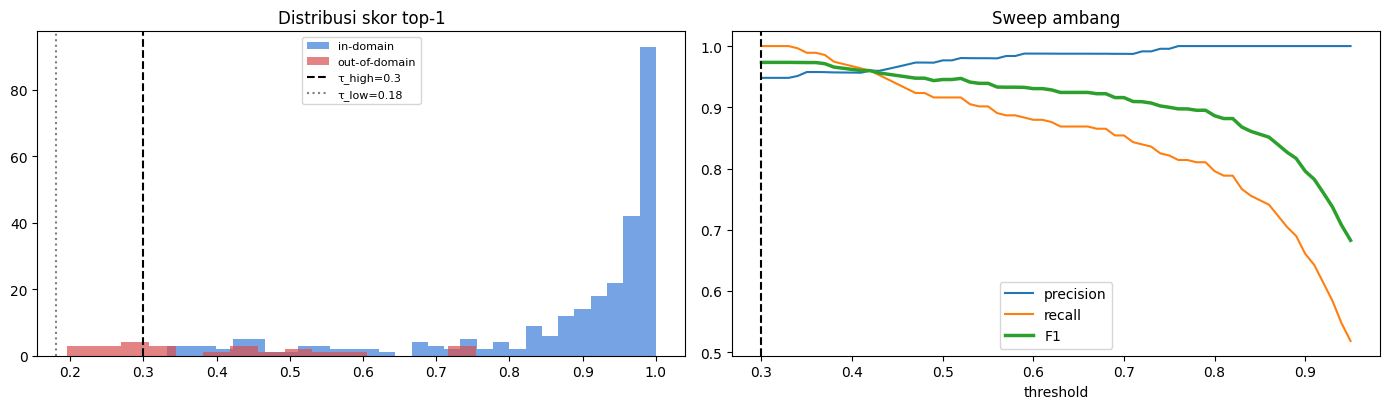


📌 Naikkan τ_high kalau prioritas Anda 'jangan sampai salah jawab'; turunkan kalau prioritasnya 'jangan terlalu sering bilang tidak tahu'. Untuk chatbot institusi resmi, condongkan ke precision.


In [ ]:
# Sweep ambang -> pilih yang memaksimalkan F1 antara "menerima yang benar"
# dan "menolak yang di luar domain"
grid = np.arange(0.30, 0.96, 0.01)
rows = []
for t in grid:
    tp = int((in_scores  >= t).sum())        # in-domain diterima  (benar)
    fn = int((in_scores  <  t).sum())        # in-domain ditolak   (salah)
    fp = int((ood_scores >= t).sum())        # OOD diterima        (salah — paling berbahaya)
    tn = int((ood_scores <  t).sum())        # OOD ditolak         (benar)
    prec = tp / (tp + fp) if tp + fp else 0
    rec  = tp / (tp + fn) if tp + fn else 0
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0
    rows.append({"threshold": round(t, 2), "precision": prec,
                 "recall": rec, "f1": f1, "ood_lolos": fp})

sweep = pd.DataFrame(rows)
best = sweep.loc[sweep["f1"].idxmax()]

TAU_HIGH = float(best["threshold"])
TAU_LOW  = round(TAU_HIGH - 0.12, 2)

print(f"τ_high (jawab langsung) = {TAU_HIGH:.2f}   F1={best['f1']:.3f}, "
      f"OOD lolos={int(best['ood_lolos'])}/{len(OOD_QUERIES)}")
print(f"τ_low  (klarifikasi)    = {TAU_LOW:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(in_scores, bins=30, alpha=.7, label="in-domain", color="#3b7dd8")
ax[0].hist(ood_scores, bins=15, alpha=.7, label="out-of-domain", color="#d94f4f")
ax[0].axvline(TAU_HIGH, color="k", ls="--", label=f"τ_high={TAU_HIGH}")
ax[0].axvline(TAU_LOW, color="gray", ls=":", label=f"τ_low={TAU_LOW}")
ax[0].set_title("Distribusi skor top-1"); ax[0].legend(fontsize=8)

ax[1].plot(sweep.threshold, sweep.precision, label="precision")
ax[1].plot(sweep.threshold, sweep.recall, label="recall")
ax[1].plot(sweep.threshold, sweep.f1, label="F1", lw=2.5)
ax[1].axvline(TAU_HIGH, color="k", ls="--")
ax[1].set_title("Sweep ambang"); ax[1].set_xlabel("threshold"); ax[1].legend()
plt.tight_layout(); plt.show()

print("\n📌 Naikkan τ_high kalau prioritas Anda 'jangan sampai salah jawab'; "
      "turunkan kalau prioritasnya 'jangan terlalu sering bilang tidak tahu'. "
      "Untuk chatbot institusi resmi, condongkan ke precision.")

## 9. Cross-Encoder Re-Ranking (Opsional)

Bi-encoder cepat tapi meng-encode query dan dokumen **terpisah**, sehingga tidak
melihat interaksi kata antar keduanya. **Cross-encoder** memproses pasangan
`[query] [SEP] [dokumen]` dalam satu forward pass — jauh lebih akurat, tapi jauh
lebih lambat (harus dijalankan per kandidat).

Pola standar: bi-encoder ambil top-20 → cross-encoder urutkan ulang jadi top-3.

> Untuk 261 FAQ, ini biasanya **belum perlu**. Jalankan sel ini hanya kalau
> Acc@1 dari Bagian 7 masih di bawah target Anda — biayanya latensi +50–150 ms.

In [ ]:
JALANKAN_RERANKER = False   # ubah ke True untuk mencoba

if JALANKAN_RERANKER:
    from sentence_transformers import CrossEncoder
    ce = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1", device=DEVICE)

    def retrieve_rerank(query, k=5, kandidat=20):
        cand = retrieve_ft(query, kandidat)
        pairs = [[normalize(query), normalize(id2q[i])] for i, _ in cand]
        scores = ce.predict(pairs)
        order = np.argsort(-scores)[:k]
        return [(cand[i][0], float(scores[i])) for i in order]

    results.append(evaluate(retrieve_rerank, test_df, CFG["top_k"], "Bi-encoder + CrossEncoder"))
    results_hard.append(evaluate(retrieve_rerank, hard_df, CFG["top_k"], "Bi-encoder + CrossEncoder"))
else:
    print("Dilewati. Set JALANKAN_RERANKER = True untuk mengaktifkan.")

Dilewati. Set JALANKAN_RERANKER = True untuk mengaktifkan.


## 10. Kelas Inference Siap-Produksi

Semua keputusan di atas dibungkus jadi satu kelas yang bisa dipindahkan apa adanya
ke FastAPI/Flask nanti. Yang ditangani:

- Tiga tingkat kepercayaan (jawab / klarifikasi / fallback)
- **Penanganan jawaban `"Perlu wawancara"`** → tidak pernah dikirim mentah ke camaba
- Sapaan & basa-basi (di-*shortcut*, tidak perlu masuk retrieval)
- Payload terstruktur untuk *logging* — bahan perbaikan dataset berikutnya

In [ ]:
class ChatbotCamaba:
    """FAQ retriever untuk PMB UBB dengan pengendalian kepercayaan berlapis."""

    SAPAAN = {
        r"^(hai|halo|hallo|hi|pagi|siang|sore|malam|assalam\w*|permisi)\b":
            "Halo! 👋 Saya asisten informasi penerimaan mahasiswa baru Universitas "
            "Bangka Belitung. Ada yang bisa saya bantu seputar jalur masuk, biaya "
            "kuliah, program studi, atau beasiswa?",
        r"^(terima kasih|makasih|thanks|tengkyu|oke|ok|siap)\b":
            "Sama-sama! Semoga sukses masuk UBB 🎓 Ada lagi yang ingin ditanyakan?",
        r"^(dadah|bye|sampai jumpa|selamat tinggal)\b":
            "Sampai jumpa! Semoga berhasil di seleksi PMB UBB.",
    }

    PESAN_ESKALASI = (
        "Untuk pertanyaan ini saya belum punya data resmi yang terverifikasi, dan "
        "saya tidak ingin memberi informasi yang keliru.\n\n"
        "Silakan hubungi Panitia PMB UBB secara langsung:\n"
        "🌐 https://www.ubb.ac.id\n"
        "📧 Bagian Akademik & Kemahasiswaan UBB"
    )

    PESAN_FALLBACK = (
        "Maaf, saya belum memahami pertanyaan Anda. 🙏\n\n"
        "Saya khusus melayani informasi seputar penerimaan mahasiswa baru UBB — "
        "misalnya jalur masuk (SNBP/SNBT/Mandiri), biaya kuliah, program studi, "
        "beasiswa, asrama, dan fasilitas kampus.\n\n"
        "Coba tanyakan dengan kalimat lain, atau hubungi https://www.ubb.ac.id"
    )

    def __init__(self, model, dataframe, tau_high, tau_low, top_k=3,
                 query_prefix="", doc_prefix=""):
        self.model, self.df = model, dataframe
        self.tau_high, self.tau_low, self.top_k = tau_high, tau_low, top_k
        self.qp, self.dp = query_prefix, doc_prefix
        self.ids = dataframe["id"].tolist()
        self.index = model.encode(
            [self.dp + normalize(q) for q in dataframe["pertanyaan"]],
            convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)

    def _sapaan(self, text):
        t = text.lower().strip()
        for pat, resp in self.SAPAAN.items():
            if re.match(pat, t):
                return resp
        return None

    def _search(self, query, k):
        emb = self.model.encode(self.qp + normalize(query),
                                convert_to_tensor=True, normalize_embeddings=True)
        hits = util.semantic_search(emb, self.index, top_k=k)[0]
        return [(int(self.ids[h["corpus_id"]]), float(h["score"])) for h in hits]

    def jawab(self, query):
        """Mengembalikan dict siap-serialisasi (cocok untuk response API + logging)."""
        query = (query or "").strip()
        if len(query) < 2:
            return {"tipe": "kosong", "jawaban": "Silakan ketik pertanyaan Anda.",
                    "skor": 0.0, "kandidat": []}

        if (s := self._sapaan(query)):
            return {"tipe": "sapaan", "jawaban": s, "skor": 1.0, "kandidat": []}

        hits = self._search(query, self.top_k)
        if not hits:
            return {"tipe": "fallback", "jawaban": self.PESAN_FALLBACK,
                    "skor": 0.0, "kandidat": []}

        doc_id, skor = hits[0]
        row = self.df.loc[self.df["id"] == doc_id].iloc[0]
        kandidat = [{"id": i, "pertanyaan": self.df.loc[self.df["id"] == i, "pertanyaan"].iloc[0],
                     "skor": round(s, 4)} for i, s in hits]

        # --- Tier 3: di luar domain ---
        if skor < self.tau_low:
            return {"tipe": "fallback", "jawaban": self.PESAN_FALLBACK,
                    "skor": skor, "kandidat": kandidat}

        # --- Tier 2: ambigu -> minta klarifikasi ---
        if skor < self.tau_high:
            opsi = "\n".join(f"{i}. {c['pertanyaan']}" for i, c in enumerate(kandidat, 1))
            return {"tipe": "klarifikasi",
                    "jawaban": f"Sepertinya maksud Anda salah satu ini:\n\n{opsi}\n\n"
                               "Silakan pilih nomornya atau ketik ulang lebih spesifik.",
                    "skor": skor, "kandidat": kandidat}

        # --- Tier 1a: yakin, tapi jawabannya belum terverifikasi ---
        if bool(row["butuh_verifikasi"]):
            return {"tipe": "eskalasi", "jawaban": self.PESAN_ESKALASI, "skor": skor,
                    "kategori": row["kategori"], "matched": row["pertanyaan"],
                    "kandidat": kandidat}

        # --- Tier 1b: yakin, jawaban dikirim VERBATIM dari Excel ---
        jawaban = row["jawaban"]
        if row["sumber"] and row["sumber"] not in {"—", "-"}:
            jawaban += f"\n\n📎 Sumber: {row['sumber']}"
        return {"tipe": "jawaban", "jawaban": jawaban, "skor": skor,
                "kategori": row["kategori"], "matched": row["pertanyaan"],
                "kandidat": kandidat}


bot = ChatbotCamaba(ft_model, df, TAU_HIGH, TAU_LOW,
                    query_prefix=CFG["query_prefix"], doc_prefix=CFG["doc_prefix"])
print("✅ Chatbot siap.")

✅ Chatbot siap.


In [ ]:
UJI = [
    "halo",
    "apa itu ubb",
    "min brp ukt di ubb",
    "prodi TI akreditasinya apa ya kak",
    "kpn snbp 2026 dibuka",
    "ada beasiswa gak buat maba",
    "jurusan kedokteran ada?",
    "berapa luas kampus ubb",             # jawaban 'Perlu wawancara' -> eskalasi
    "cara masak rendang padang",          # di luar domain -> fallback
    "makasih ya",
]

IKON = {"jawaban": "✅", "klarifikasi": "❓", "eskalasi": "📞",
        "fallback": "🚫", "sapaan": "👋", "kosong": "…"}

for q in UJI:
    r = bot.jawab(q)
    print(f"\n{'─'*78}\n👤 {q}\n{IKON[r['tipe']]} [{r['tipe']} | skor {r['skor']:.3f}]")
    print("🤖", r["jawaban"][:340] + ("..." if len(r["jawaban"]) > 340 else ""))


──────────────────────────────────────────────────────────────────────────────
👤 halo
👋 [sapaan | skor 1.000]
🤖 Halo! 👋 Saya asisten informasi penerimaan mahasiswa baru Universitas Bangka Belitung. Ada yang bisa saya bantu seputar jalur masuk, biaya kuliah, program studi, atau beasiswa?

──────────────────────────────────────────────────────────────────────────────
👤 apa itu ubb
✅ [jawaban | skor 0.995]
🤖 Universitas Bangka Belitung (UBB) adalah Perguruan Tinggi Negeri (PTN) di Provinsi Kepulauan Bangka Belitung yang menyelenggarakan pendidikan, penelitian, dan pengabdian kepada masyarakat dengan orientasi sebagai universitas riset berbasis pembangunan berkelanjutan.

📎 Sumber: Profil UBB

──────────────────────────────────────────────────────────────────────────────
👤 min brp ukt di ubb
✅ [jawaban | skor 0.893]
🤖 Besaran Uang Kuliah Tunggal (UKT) di Universitas Bangka Belitung berbeda pada setiap program studi dan kelompok UKT. UBB menetapkan beberapa kelompok UKT mulai dari kelompok

## 11. Demo Interaktif (Gradio)

Antarmuka untuk uji coba bersama tim PMB. Jalankan sel, lalu buka URL publik yang
muncul — link `share=True` aktif 72 jam, cukup untuk sesi UAT.

In [ ]:
import gradio as gr

def chat_fn(pesan, riwayat):
    r = bot.jawab(pesan)
    meta = f"\n\n<sub>`{r['tipe']}` · skor {r['skor']:.3f}</sub>"
    return r["jawaban"] + meta

demo = gr.ChatInterface(
    fn=chat_fn,
    title="🎓 Asisten PMB Universitas Bangka Belitung 2026",
    description="Prototipe chatbot informasi penerimaan mahasiswa baru. "
                "Jawaban diambil verbatim dari basis data resmi UBB.",
    examples=["Apa itu UBB?", "Berapa biaya kuliah di UBB?",
              "Kapan SNBP 2026 dibuka?", "Ada beasiswa apa saja?",
              "Fakultas apa saja yang ada?"],
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://539001d2deabaf7c4e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12. Export Artefak

Yang perlu dibawa ke production: **model**, **index embedding**, **knowledge base**,
dan **konfigurasi ambang**. Simpan semuanya sebagai satu paket berversi.

In [ ]:
import shutil, datetime

OUT = Path(CFG["output_dir"]) / "chatbot_camaba_ubb_v1"
OUT.mkdir(parents=True, exist_ok=True)

# 1) Model hasil fine-tuning
ft_model.save(str(OUT / "model"))

# 2) Knowledge base (jawaban dikirim dari sini, bukan digenerate model)
df.to_json(OUT / "knowledge_base.json", orient="records",
           force_ascii=False, indent=2)

# 3) Index embedding pra-hitung -> hindari re-encode saat service start
np.save(OUT / "index_embeddings.npy", index_ft.cpu().numpy())

# 4) Konfigurasi runtime
config = {
    "versi": "1.0",
    "dibuat": datetime.datetime.now().isoformat(timespec="seconds"),
    "model_dasar": CFG["model_name"],
    "query_prefix": CFG["query_prefix"],
    "doc_prefix": CFG["doc_prefix"],
    "tau_high": TAU_HIGH,
    "tau_low": TAU_LOW,
    "top_k": CFG["top_k"],
    "jumlah_faq": int(len(df)),
    "butuh_verifikasi": int(df["butuh_verifikasi"].sum()),
    "metrik": res_df.to_dict("index"),
}
(OUT / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))

# 5) Laporan error untuk perbaikan dataset
if len(err):
    err.to_csv(OUT / "error_analysis.csv", index=False)

shutil.make_archive(str(OUT), "zip", OUT)
print(json.dumps(config, indent=2, ensure_ascii=False)[:900])
print(f"\n📦 Paket: {OUT}.zip")

# Unduh / simpan ke Drive
# from google.colab import files; files.download(f"{OUT}.zip")
# shutil.copy(f"{OUT}.zip", "/content/drive/MyDrive/")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "versi": "1.0",
  "dibuat": "2026-08-24T12:20:08",
  "model_dasar": "LazarusNLP/all-indo-e5-small-v4",
  "query_prefix": "",
  "doc_prefix": "",
  "tau_high": 0.3,
  "tau_low": 0.18,
  "top_k": 5,
  "jumlah_faq": 260,
  "butuh_verifikasi": 70,
  "metrik": {
    "TF-IDF (word+char)": {
      "Acc@1 [augment]": 0.9916,
      "Acc@3 [augment]": 1.0,
      "MRR@5 [augment]": 0.9958,
      "Acc@1 [hard]": 0.0556,
      "Acc@3 [hard]": 0.0833,
      "MRR@5 [hard]": 0.0694
    },
    "Bi-encoder (zero-shot)": {
      "Acc@1 [augment]": 0.979,
      "Acc@3 [augment]": 1.0,
      "MRR@5 [augment]": 0.9895,
      "Acc@1 [hard]": 0.1389,
      "Acc@3 [hard]": 0.3333,
      "MRR@5 [hard]": 0.2574
    },
    "Bi-encoder (fine-tuned)": {
      "Acc@1 [augment]": 0.9916,
      "Acc@3 [augment]": 1.0,
      "MRR@5 [augment]": 0.9958,
      "Acc@1 [hard]": 0.0833,
      "Acc@3 [hard]": 0.2778,
      

📦 Paket: artifacts/chatbot_camaba_ubb_v1.zip


In [ ]:
# Opsional: publikasikan ke Hugging Face Hub (repo privat untuk internal)
# from huggingface_hub import notebook_login
# notebook_login()
# ft_model.push_to_hub("diskominfo-pangkalpinang/chatbot-camaba-ubb-2026", private=True)

## 13. Catatan Menuju Production

### 13.1 Perbaikan dataset — dampaknya paling besar, biayanya paling murah

Sebelum menyentuh arsitektur, benahi dulu Excel-nya. Urutan prioritas:

1. **Tuntaskan ±68 jawaban `"Perlu wawancara"`.** Ini ¼ dari basis pengetahuan.
   Selama masih placeholder, 1 dari 4 pertanyaan berujung eskalasi manual.
2. **Gabungkan intent kembar.** `"Fakultas Hukum ada?"` dan `"Jurusan Hukum ada?"`
   adalah intent yang sama; menyimpan keduanya sebagai entri terpisah menciptakan
   ambiguitas yang tidak bisa diselesaikan model mana pun.
3. **Tambahkan kolom `variasi_pertanyaan`** di Excel — 3–5 parafrase tulisan manusia
   per baris. Parafrase asli selalu mengalahkan augmentasi rule-based; ini cara
   tercepat menaikkan akurasi.
4. **Tambahkan kolom `terakhir_diverifikasi`.** Data PMB kedaluwarsa tiap tahun.
   Tanpa ini, tidak ada yang tahu entri mana yang sudah basi.

### 13.2 Log produksi adalah aset terbesar Anda

Simpan setiap `{query, tipe, skor, matched_id, timestamp}`. Dari sana:

- Query bertipe `fallback` = **pertanyaan yang hilang dari FAQ** → antrean penambahan konten
- Query bertipe `klarifikasi` = **intent yang ambigu** → antrean perapian dataset
- Log 3 bulan pertama = data training nyata untuk fine-tuning putaran kedua

Sediakan tombol 👍/👎 di UI. Sinyal negatif adalah *hard negative* berkualitas tinggi
untuk MNRL — jauh lebih bernilai daripada tambahan data sintetis.

### 13.3 Arsitektur deployment

```
Nginx ──▶ FastAPI ──▶ ChatbotCamaba (model + index di memori)
                          │
                          ├─▶ PostgreSQL  (log percakapan)
                          └─▶ Redis       (cache query populer, TTL 1 jam)
```

- Model 384-dim + 261 dokumen ≈ **400 MB RAM**; CPU sudah cukup, **tidak perlu GPU**.
- Latensi target < 200 ms; cache Redis menangani ekor query populer ("berapa UKT").
- Muat model **sekali saat startup** (`lifespan` FastAPI), bukan per-request.
- Untuk skala > 10.000 dokumen, ganti `util.semantic_search` dengan FAISS/Qdrant.
  Di angka 261, itu justru menambah kompleksitas tanpa manfaat.

### 13.4 Re-indexing saat data berubah

Setiap update Excel → jalankan ulang parsing + `build_index` → simpan `.npy` baru.
Cukup jadikan skrip cron. **Fine-tuning tidak perlu diulang** kecuali penambahan
kontennya besar (> 30% entri baru).

### 13.5 Kapan LLM generatif layak ditambahkan

Hanya sebagai **lapisan penulisan ulang di atas hasil retrieval**, bukan pengganti:

```
retrieval (fakta) ──▶ LLM: "susun ulang jawaban ini agar lebih ramah,
                            JANGAN menambah informasi apa pun"
```

Sumber faktanya tetap Excel — ini menjaga auditabilitas sambil membuat gaya bahasanya
lebih luwes. Kalau ini ditempuh, tetap tampilkan `📎 Sumber` supaya jawaban bisa
ditelusuri.

### 13.6 Checklist sebelum go-live

- [ ] Semua jawaban `"Perlu wawancara"` sudah final atau sudah diarahkan ke eskalasi
- [ ] Acc@1 ≥ 0,85 pada test set
- [ ] Nol query out-of-domain lolos di atas `τ_high` (uji dengan ≥ 100 query OOD)
- [ ] Rate limiting per IP (cegah penyalahgunaan endpoint publik)
- [ ] Sanitasi input (batas panjang, tolak payload aneh)
- [ ] Halaman fallback dengan kontak PMB yang benar & aktif
- [ ] Disclaimer: *"Informasi bersifat indikatif; keputusan resmi mengacu pada pengumuman UBB."*
- [ ] UAT bersama Panitia PMB memakai pertanyaan camaba tahun sebelumnya

---

**Susunan file hasil export**

```
chatbot_camaba_ubb_v1/
├── model/                  # SentenceTransformer hasil fine-tuning
├── knowledge_base.json     # sumber jawaban (verbatim)
├── index_embeddings.npy    # embedding pra-hitung
├── config.json             # ambang + metrik + versi
└── error_analysis.csv      # bahan perbaikan dataset
```